<a href="https://colab.research.google.com/github/thegurdian/ML/blob/main/d1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Target Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Missing Values:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Age Group Distribution:
Age_Group
21-30    417
31-40    157
41-50    113
51+       81
Name: count, dtype: int64

Diabetes Prevalence by Age Group:
Age_Group
21-30    21.58
31-40    48.41
41-50    56.64
51+      46.91
Name: Outcome, dtype: float64


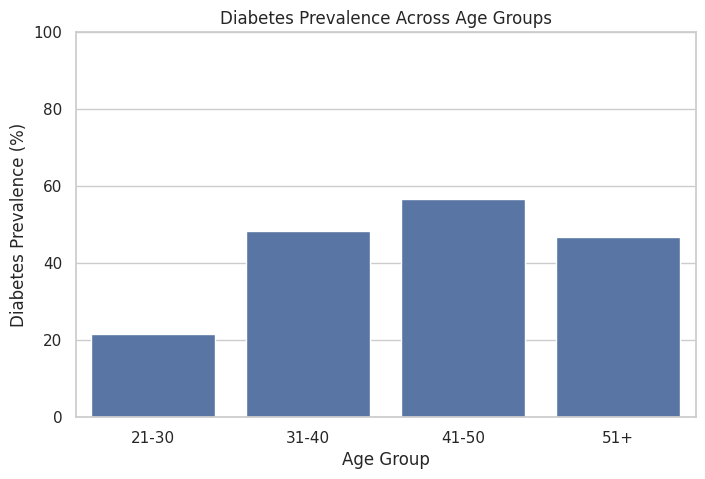

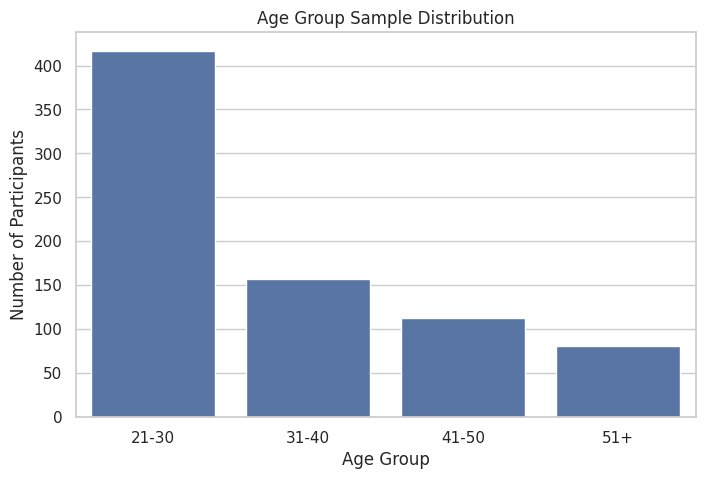


Age Group and Diabetes Status:


,Non-Diabetic,Diabetic
Age_Group,,
21-30,327,90
31-40,81,76
41-50,49,64
51+,43,38


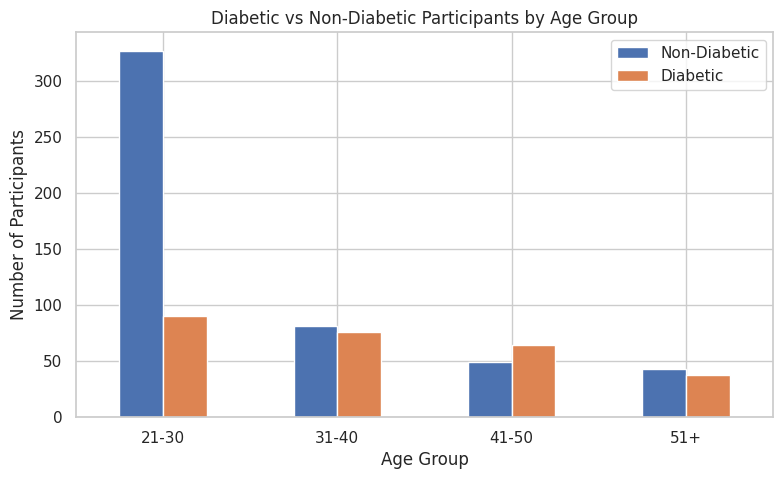

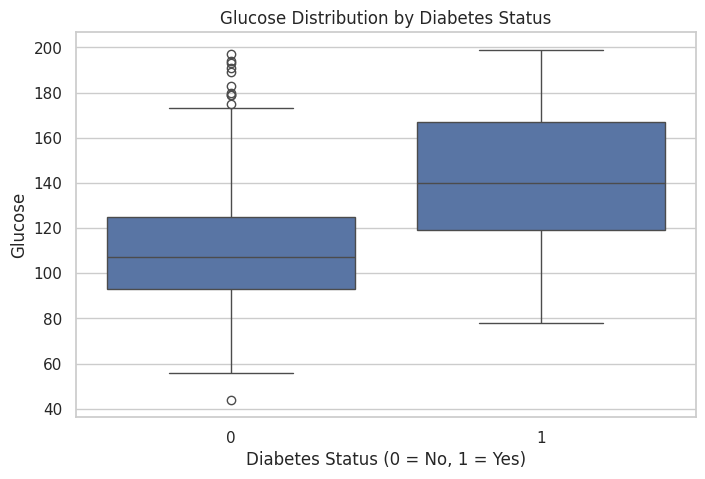

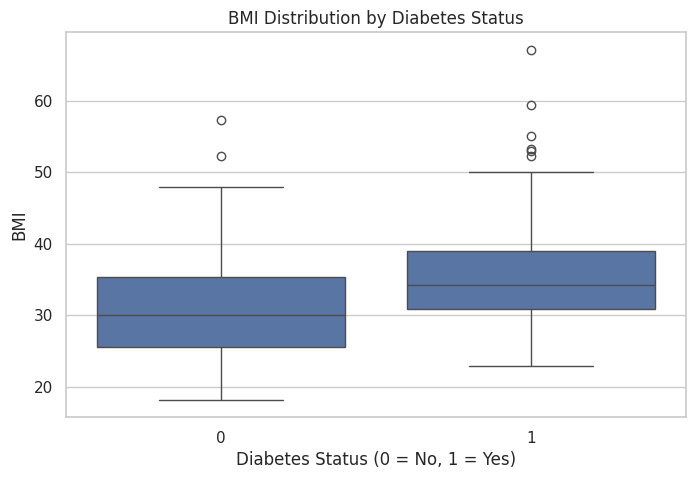

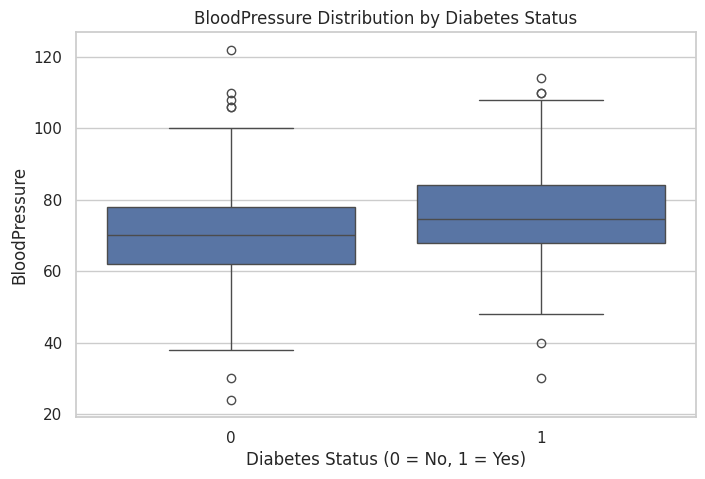

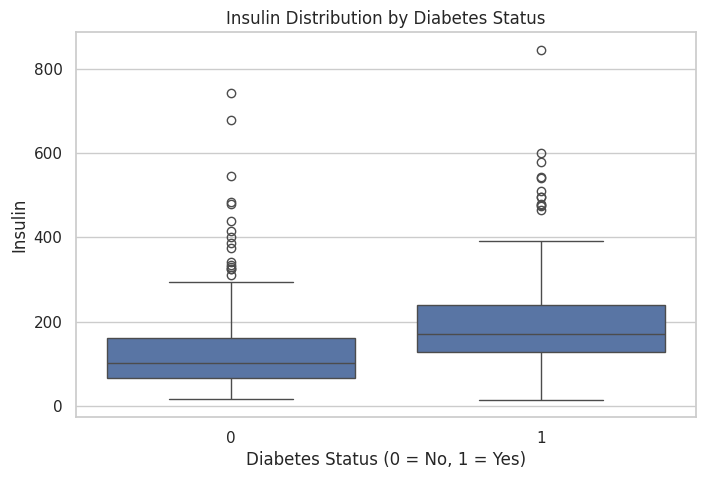

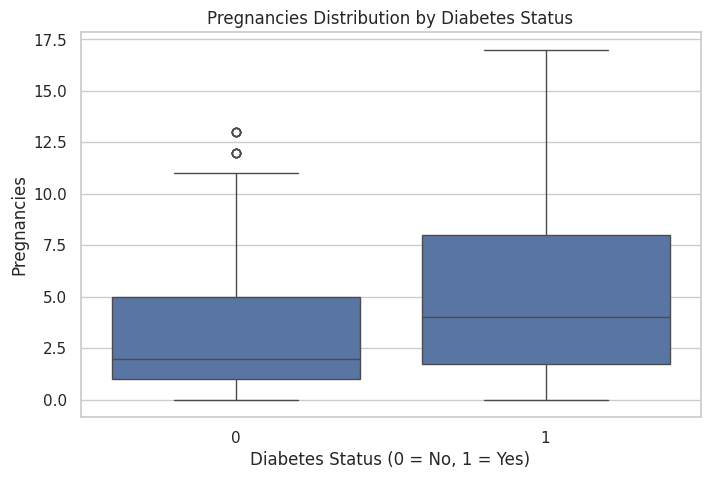

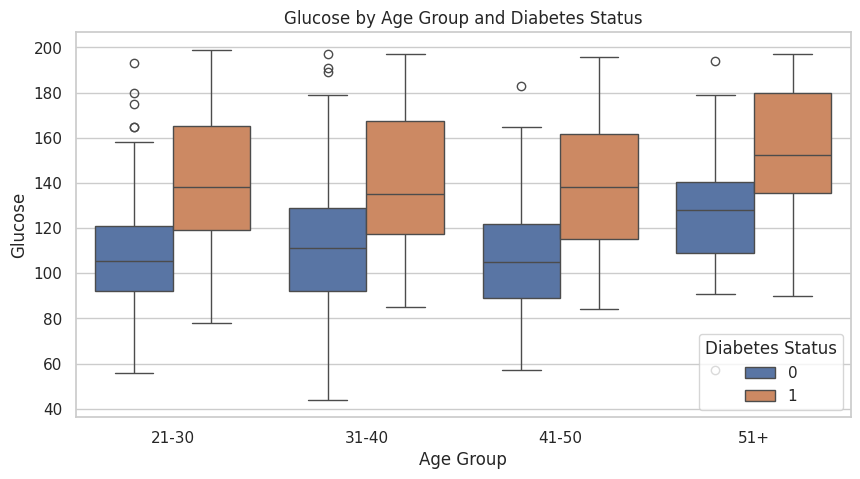

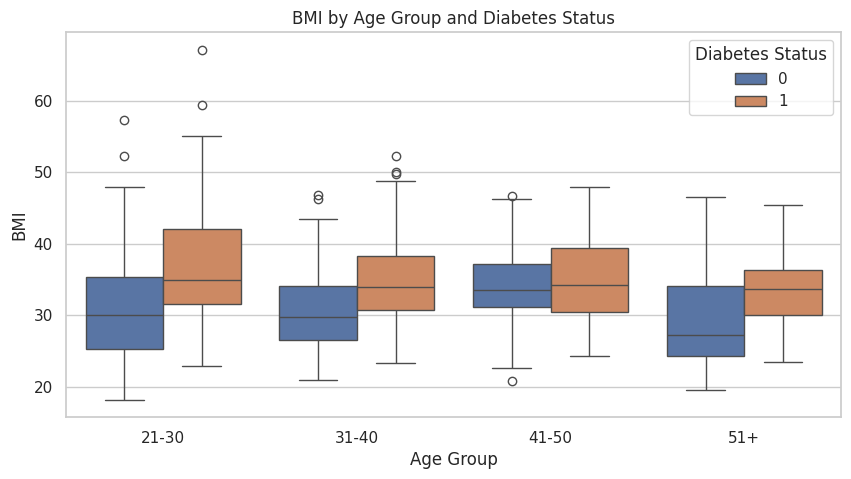

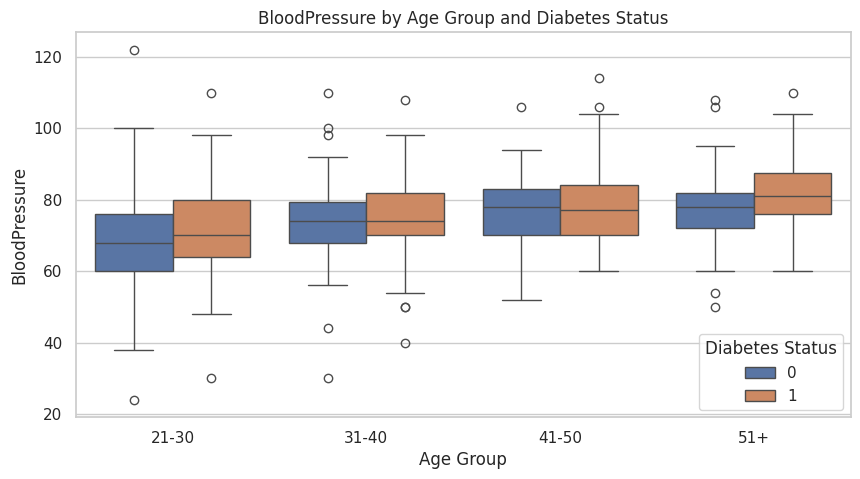

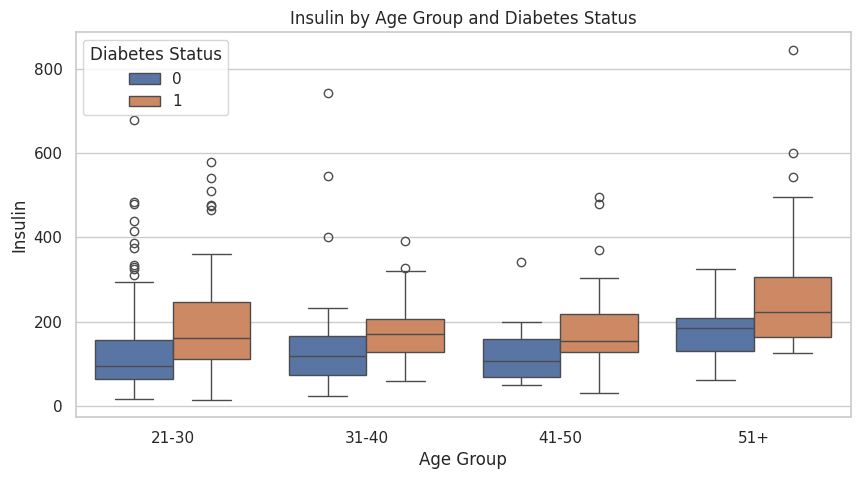

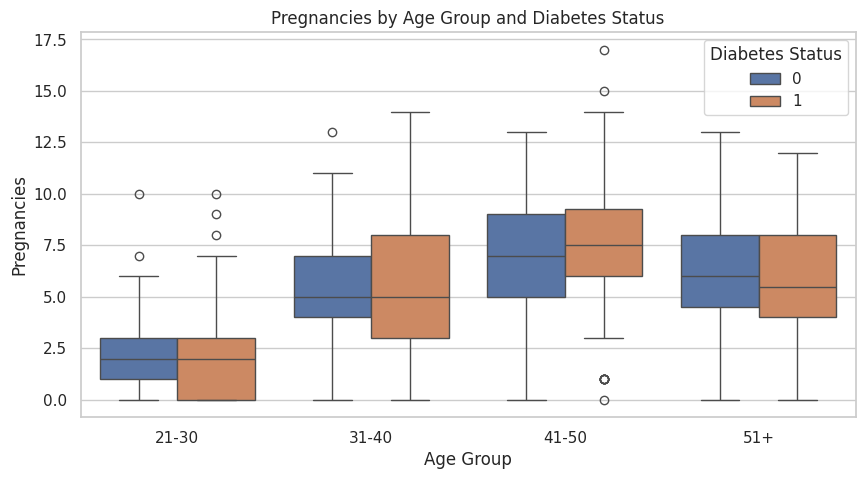

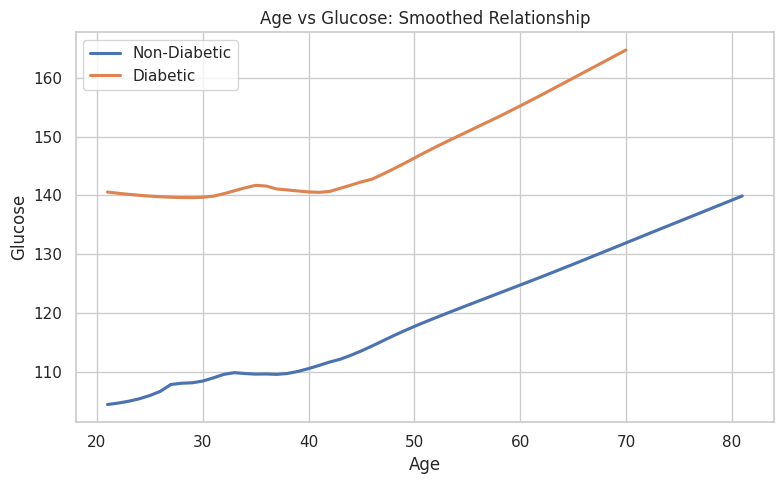

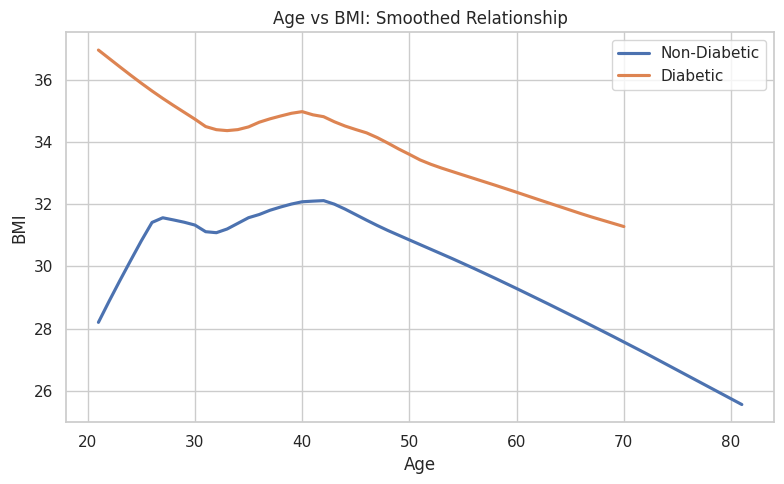

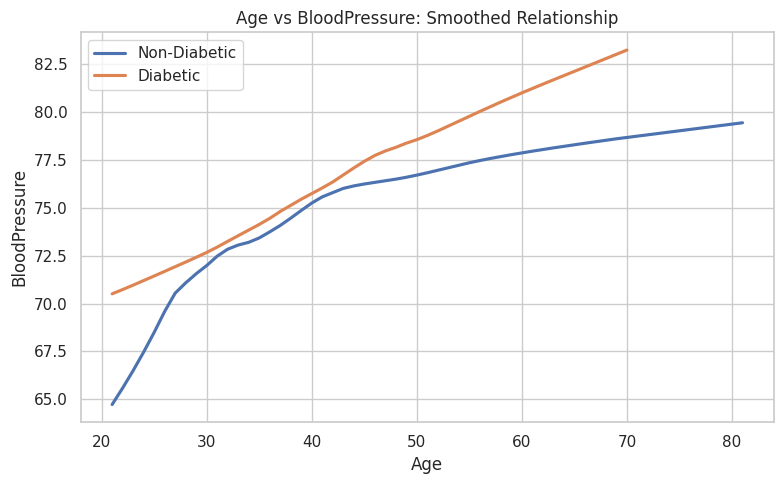

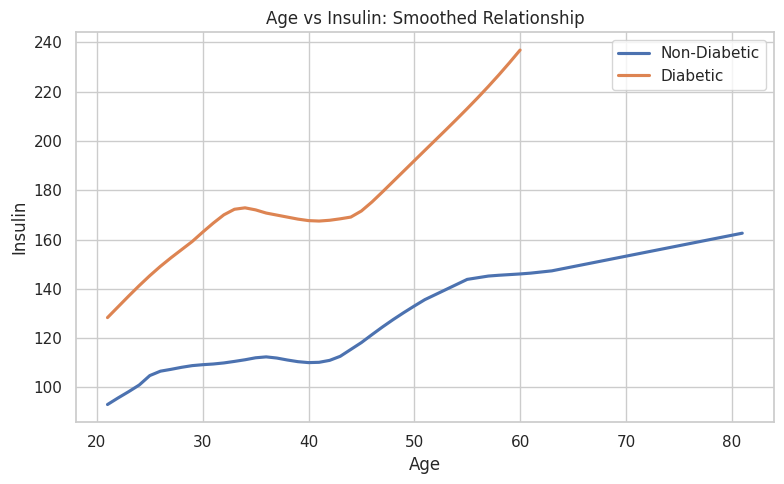

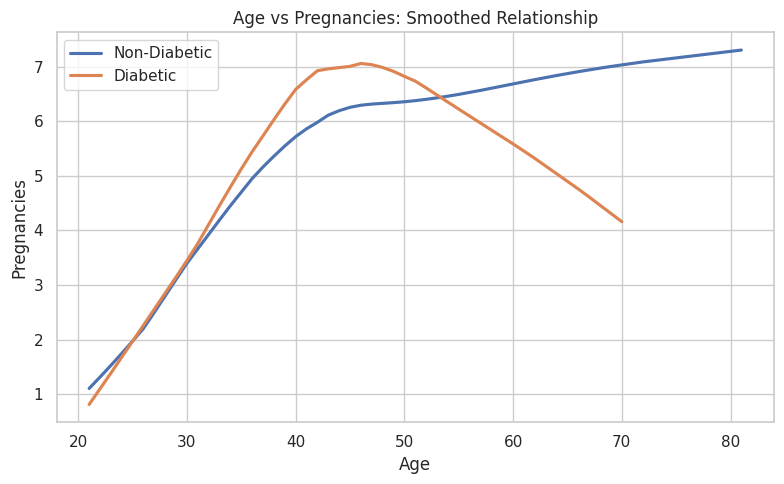


Training Samples: 614
Testing Samples: 154

Normal Bagging Training Completed.

Age Group: 21-30
Samples: 328
Class Distribution:
Outcome
0    256
1     72
Name: count, dtype: int64
Local model trained.

Age Group: 31-40
Samples: 130
Class Distribution:
Outcome
0    72
1    58
Name: count, dtype: int64
Local model trained.

Age Group: 41-50
Samples: 89
Class Distribution:
Outcome
1    51
0    38
Name: count, dtype: int64
Local model trained.

Age Group: 51+
Samples: 67
Class Distribution:
Outcome
0    34
1    33
Name: count, dtype: int64
Local model trained.

Age-Based Prediction Completed.

FINAL MODEL COMPARISON:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Normal Bagging,0.7273,0.6364,0.5185,0.5714,0.8102
1,Age-Based Bagging,0.7468,0.6364,0.6481,0.6422,0.7817


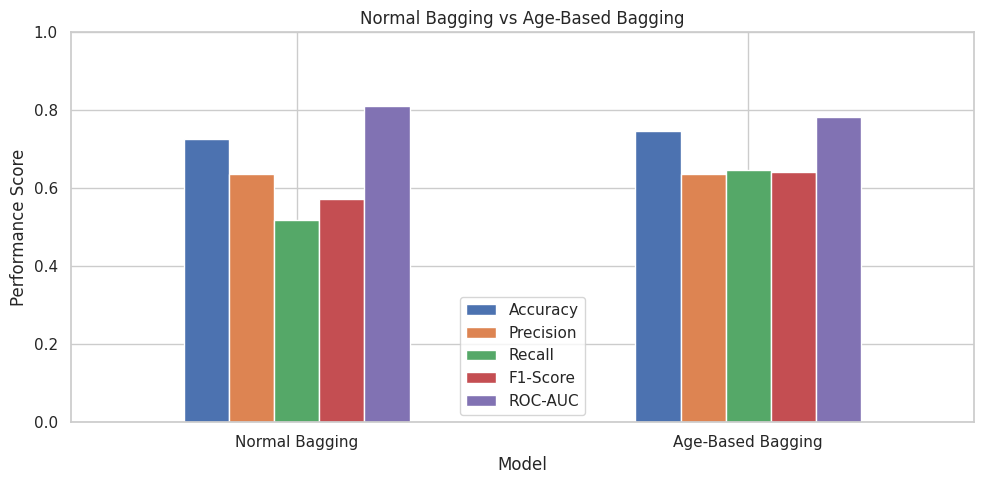

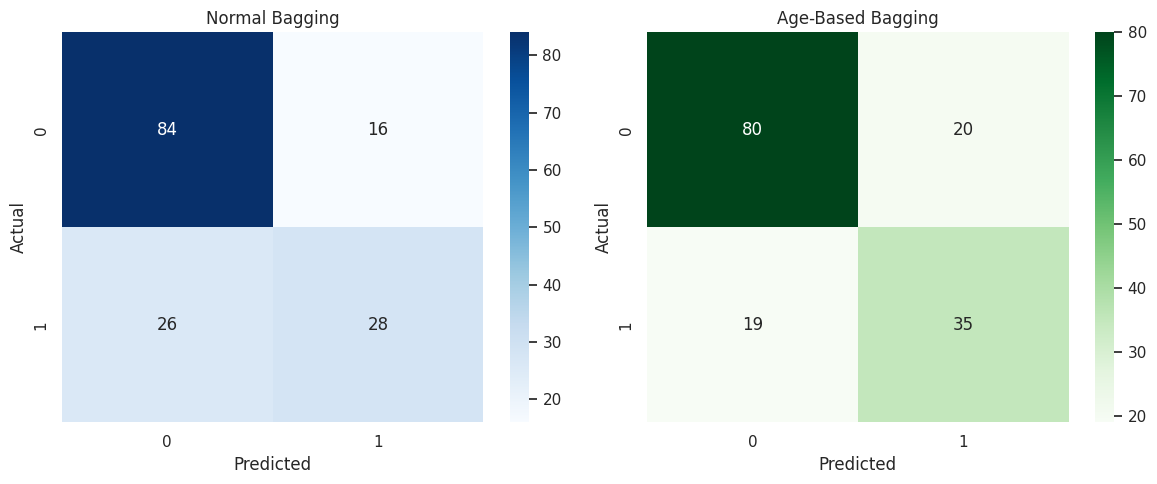


AGE-WISE PERFORMANCE:


,Age Group,Samples,Normal Accuracy,Age-Based Accuracy,Normal Recall,Age-Based Recall
0,21-30,89,0.7753,0.7865,0.3333,0.5000
1,31-40,27,0.5556,0.6296,0.5000,0.5556
2,41-50,24,0.7917,0.8333,0.7692,0.9231
3,51+,14,0.6429,0.5714,0.6000,0.8000


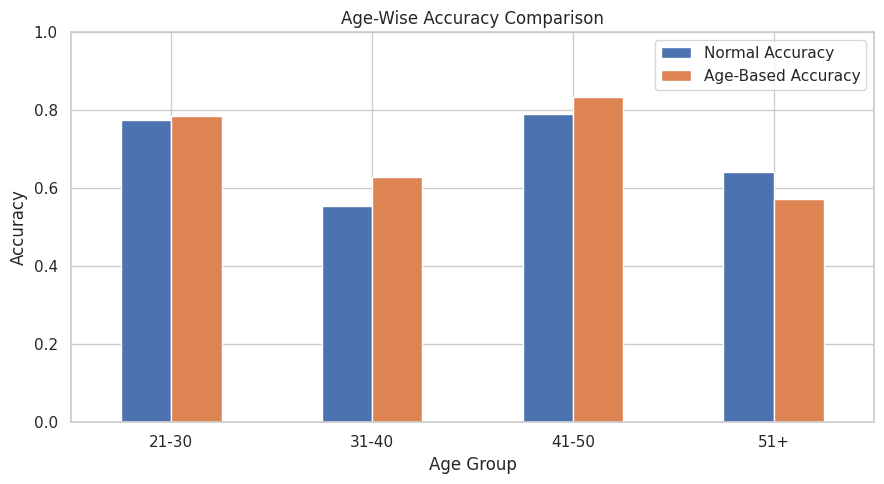


EXPERIMENT COMPLETED!


In [ ]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

sns.set_theme(style="whitegrid")


# ============================================================
# 2. LOAD DATASET
# ============================================================

# The Pima Indians Diabetes Dataset with standard column names
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
column_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

data = pd.read_csv(url, names=column_names)
X = data.drop(columns=["Outcome"]).copy()
y = data["Outcome"].copy()

print("Dataset Shape:", data.shape)
display(data.head())

print("\nTarget Distribution:")
print(data["Outcome"].value_counts())


# ============================================================
# 3. DATA CLEANING
# ============================================================

# Zero values in these medical features are treated as missing.

invalid_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in invalid_columns:
    data.loc[data[col] == 0, col] = np.nan

# Remove rows with missing target values, if any
data = data.dropna(subset=["Outcome"]).copy()
data["Outcome"] = data["Outcome"].astype(int)

print("\nMissing Values:")
print(data.isnull().sum())


# ============================================================
# 4. CREATE AGE GROUPS
# ============================================================

age_groups = ["21-30", "31-40", "41-50", "51+"]

data["Age_Group"] = pd.cut(
    data["Age"],
    bins=[20, 30, 40, 50, 100],
    labels=age_groups,
    include_lowest=True
)

print("\nAge Group Distribution:")
print(data["Age_Group"].value_counts().sort_index())


# ============================================================
# 5. AGE-WISE DIABETES PREVALENCE
# ============================================================

age_prevalence = (
    data.groupby("Age_Group", observed=False)["Outcome"].mean() * 100
)

print("\nDiabetes Prevalence by Age Group:")
print(age_prevalence.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=age_prevalence.index,
    y=age_prevalence.values
)

plt.title("Diabetes Prevalence Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Diabetes Prevalence (%)")
plt.ylim(0, 100)

plt.show()


# ============================================================
# 6. AGE GROUP SAMPLE DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="Age_Group",
    order=age_groups
)

plt.title("Age Group Sample Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Participants")

plt.show()


# ============================================================
# 7. DIABETIC VS NON-DIABETIC COUNT BY AGE
# ============================================================

age_status_count = pd.crosstab(
    data["Age_Group"],
    data["Outcome"]
)

age_status_count.columns = [
    "Non-Diabetic",
    "Diabetic"
]

print("\nAge Group and Diabetes Status:")
display(age_status_count)

age_status_count.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Diabetic vs Non-Diabetic Participants by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Participants")
plt.xticks(rotation=0)
plt.show()


# ============================================================
# 8. FEATURE DISTRIBUTION BY DIABETES STATUS
# ============================================================

features = [
    "Glucose",
    "BMI",
    "BloodPressure",
    "Insulin",
    "Pregnancies"
]

for feature in features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=data,
        x="Outcome",
        y=feature
    )

    plt.title(f"{feature} Distribution by Diabetes Status")
    plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
    plt.ylabel(feature)

    plt.show()


# ============================================================
# 9. FEATURE DISTRIBUTION BY AGE AND DIABETES STATUS
# ============================================================

for feature in features:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=data,
        x="Age_Group",
        y=feature,
        hue="Outcome",
        order=age_groups
    )

    plt.title(f"{feature} by Age Group and Diabetes Status")
    plt.xlabel("Age Group")
    plt.ylabel(feature)
    plt.legend(title="Diabetes Status")

    plt.show()


# ============================================================
# 10. AGE-FEATURE INTERACTION INVESTIGATION
# ============================================================

interaction_features = [
    "Glucose",
    "BMI",
    "BloodPressure",
    "Insulin",
    "Pregnancies"
]

for feature in interaction_features:

    plt.figure(figsize=(8, 5))

    for status in [0, 1]:

         subset = data[data["Outcome"] == status]

         sns.regplot(
             data=subset,
             x="Age",
             y=feature,
             lowess=True,
             scatter_kws={"alpha": 0.25},
             scatter=False,
             label="Diabetic" if status == 1 else "Non-Diabetic"
         )

    plt.title(f"Age vs {feature}: Smoothed Relationship")
    plt.xlabel("Age")
    plt.ylabel(feature)
    plt.legend()

    plt.tight_layout()
    plt.show()


# ============================================================
# 11. PREPARE DATA FOR MACHINE LEARNING
# ============================================================

X = data.drop(
    columns=["Outcome", "Age_Group"]
)

y = data["Outcome"]

# Same training and testing data for both models

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# ============================================================
# 12. MODEL A: NORMAL BAGGING
# ============================================================

# Imputation is performed inside the pipeline.
# Therefore, the median is learned only from training data.

model_A = make_pipeline(

    SimpleImputer(strategy="median"),

    BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
)

model_A.fit(X_train, y_train)

pred_A = model_A.predict(X_test)

prob_A = model_A.predict_proba(X_test)[:, 1]

print("\nNormal Bagging Training Completed.")


# ============================================================
# 13. MODEL B: AGE-BASED BAGGING
# ============================================================

age_models = {}

train_age_groups = pd.cut(
    X_train["Age"],
    bins=[20, 30, 40, 50, 100],
    labels=age_groups,
    include_lowest=True
)

for group in age_groups:

    group_index = train_age_groups == group

    X_group = X_train.loc[group_index]
    y_group = y_train.loc[group_index]

    print("\nAge Group:", group)
    print("Samples:", len(X_group))
    print("Class Distribution:")
    print(y_group.value_counts())

    # Train local model only when enough samples
    # and both classes are available.

    if (
        len(X_group) >= 40
        and y_group.value_counts().min() >= 5
    ):

        model = make_pipeline(

            SimpleImputer(strategy="median"),

            BaggingClassifier(
                estimator=DecisionTreeClassifier(random_state=42),
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )

        model.fit(X_group, y_group)

        age_models[group] = model

        print("Local model trained.")

    else:

        age_models[group] = None

        print("Insufficient data. Global model will be used.")


# ============================================================
# 14. PREDICTION USING AGE-BASED MODELS
# ============================================================

pred_B = []
prob_B = []

for index, row in X_test.iterrows():

    age = row["Age"]

    if age <= 30:
        group = "21-30"

    elif age <= 40:
        group = "31-40"

    elif age <= 50:
        group = "41-50"

    else:
        group = "51+"

    # Select local model or global fallback

    if age_models[group] is not None:
        selected_model = age_models[group]

    else:
        selected_model = model_A

    sample = row.to_frame().T

    prediction = selected_model.predict(sample)[0]

    probability = selected_model.predict_proba(sample)[0, 1]

    pred_B.append(prediction)
    prob_B.append(probability)

pred_B = np.array(pred_B)
prob_B = np.array(prob_B)

print("\nAge-Based Prediction Completed.")


# ============================================================
# 15. MODEL PERFORMANCE COMPARISON
# ============================================================

results = pd.DataFrame({

    "Model": [
        "Normal Bagging",
        "Age-Based Bagging"
    ],

    "Accuracy": [
        accuracy_score(y_test, pred_A),
        accuracy_score(y_test, pred_B)
    ],

    "Precision": [
        precision_score(y_test, pred_A, zero_division=0),
        precision_score(y_test, pred_B, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, pred_A, zero_division=0),
        recall_score(y_test, pred_B, zero_division=0)
    ],

    "F1-Score": [
        f1_score(y_test, pred_A, zero_division=0),
        f1_score(y_test, pred_B, zero_division=0)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, prob_A),
        roc_auc_score(y_test, prob_B)
    ]
})

print("\nFINAL MODEL COMPARISON:")
display(results.round(4))


# ============================================================
# 16. PERFORMANCE COMPARISON GRAPH
# ============================================================

results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Normal Bagging vs Age-Based Bagging")
plt.ylabel("Performance Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()


# ============================================================
# 17. CONFUSION MATRIX COMPARISON
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, pred_A),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Normal Bagging")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, pred_B),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Age-Based Bagging")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


# ============================================================
# 18. AGE-WISE MODEL PERFORMANCE
# ============================================================

test_results = X_test.copy()

test_results["Age_Group"] = pd.cut(
    test_results["Age"],
    bins=[20, 30, 40, 50, 100],
    labels=age_groups,
    include_lowest=True
)

test_results["Actual"] = y_test
test_results["Normal_Prediction"] = pred_A
test_results["Age_Prediction"] = pred_B

age_results = []

for group in age_groups:

    group_data = test_results[
        test_results["Age_Group"] == group
    ]

    if len(group_data) == 0:
        continue

    age_results.append({

        "Age Group": group,

        "Samples": len(group_data),

        "Normal Accuracy": accuracy_score(
            group_data["Actual"],
            group_data["Normal_Prediction"]
        ),

        "Age-Based Accuracy": accuracy_score(
            group_data["Actual"],
            group_data["Age_Prediction"]
        ),

        "Normal Recall": recall_score(
            group_data["Actual"],
            group_data["Normal_Prediction"],
            zero_division=0
        ),

        "Age-Based Recall": recall_score(
            group_data["Actual"],
            group_data["Age_Prediction"],
            zero_division=0
        )
    })

age_results = pd.DataFrame(age_results)

print("\nAGE-WISE PERFORMANCE:")
display(age_results.round(4))


# ============================================================
# 19. AGE-WISE PERFORMANCE GRAPH
# ============================================================

age_results.set_index("Age Group")[
    ["Normal Accuracy", "Age-Based Accuracy"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Age-Wise Accuracy Comparison")
plt.xlabel("Age Group")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()


print("\nEXPERIMENT COMPLETED!")